# label distribution across data splits

Compare the eight emotion labels in **TRAIN**, **DEV** and **TEST** using the Swedish (`sv`) files.

The English and Swedish files contain aligned examples with the same labels. The first table summarizes the **total number of examples across both languages** in each split, as well as the number of English and Swedish examples separately. The label analysis uses only the Swedish side to avoid counting the same paired label set twice.


In [24]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

LANGUAGE = "sv"
SPLITS = ("train", "dev", "test")
EMOTIONS = (
    "anger", "anticipation", "disgust", "fear",
    "joy", "sadness", "surprise", "trust",
)

# find the project root when running from the root or notebooks/ folder
PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "processed" / LANGUAGE).is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find data/processed/sv; open the notebook inside the project")

DATA_DIR = PROJECT_ROOT / "data" / "processed" / LANGUAGE
print("Data folder:", DATA_DIR)

Data folder: /scratch/s6865704/llm/LLM_sentiment_classification/data/processed/sv


In [25]:
def load_labels(split):
    path = DATA_DIR / f"{split}_{LANGUAGE}.jsonl"
    labels_per_example = []

    with path.open(encoding="utf-8") as file:
        for line_number, line in enumerate(file, 1):
            if not line.strip():
                continue
            row = json.loads(line)
            labels = row["output"]
            if isinstance(labels, str):
                labels = json.loads(labels)
            if not isinstance(labels, list):
                raise ValueError(f"Expected a label list in {path.name}, line {line_number}")
            unknown = set(labels) - set(EMOTIONS)
            if unknown:
                raise ValueError(f"Unknown labels {unknown} in {path.name}, line {line_number}")
            labels_per_example.append(set(labels))

    return labels_per_example


def load_split_rows(split, language):
    path = DATA_DIR / f"{split}_{language}.jsonl"
    with path.open(encoding="utf-8") as file:
        return [json.loads(line) for line in file if line.strip()]


split_labels = {split: load_labels(split) for split in SPLITS}
split_sizes = {split: len(rows) for split, rows in split_labels.items()}

# summarize the original aligned data, not the balanced bilingual training file
summary_rows = []
for split in SPLITS:
    english_rows = load_split_rows(split, "en")
    swedish_rows = load_split_rows(split, LANGUAGE)

    english_ids = [row["alignment_id"] for row in english_rows]
    swedish_ids = [row["alignment_id"] for row in swedish_rows]

    if len(english_ids) != len(set(english_ids)) or len(swedish_ids) != len(set(swedish_ids)):
        raise ValueError(f"Duplicate alignment IDs in {split}")
    if set(english_ids) != set(swedish_ids):
        raise ValueError(f"English and Swedish alignment IDs do not match in {split}")
    if len(swedish_rows) != split_sizes[split]:
        raise ValueError(f"Swedish label counts do not match the records in {split}")

    summary_rows.append({
        "Language": "Swedish",
        "Split": split,
        "Total examples": len(english_rows) + len(swedish_rows),
        "English examples": len(english_rows),
        "Swedish examples": len(swedish_rows),
        "Labels / item": round(
            sum(len(labels) for labels in split_labels[split]) / len(swedish_rows), 2
        ),
    })

split_summary = pd.DataFrame(summary_rows)
display(split_summary)


,Language,Split,Total examples,English examples,Swedish examples,Labels / item
0,Swedish,train,3466,1733,1733,1.44
1,Swedish,dev,994,497,497,1.44
2,Swedish,test,500,250,250,1.42


In [26]:
# count how many examples contain each emotion
counts = pd.DataFrame({
    split: Counter(label for labels in split_labels[split] for label in labels)
    for split in SPLITS
}).reindex(EMOTIONS, fill_value=0)
counts.index.name = "emotion"

# percentages make the different split sizes comparable
percentages = counts.div(pd.Series(split_sizes), axis="columns") * 100

print("Label counts:")
display(counts)

print("Percentage of examples containing each label:")
display(percentages.round(1))

Label counts:


,train,dev,test
emotion,,,
anger,436,125,62
anticipation,415,119,59
disgust,235,67,34
fear,236,67,34
joy,269,77,38
sadness,310,89,44
surprise,294,84,42
trust,304,87,43


Percentage of examples containing each label:


,train,dev,test
emotion,,,
anger,25.2,25.2,24.8
anticipation,23.9,23.9,23.6
disgust,13.6,13.5,13.6
fear,13.6,13.5,13.6
joy,15.5,15.5,15.2
sadness,17.9,17.9,17.6
surprise,17.0,16.9,16.8
trust,17.5,17.5,17.2


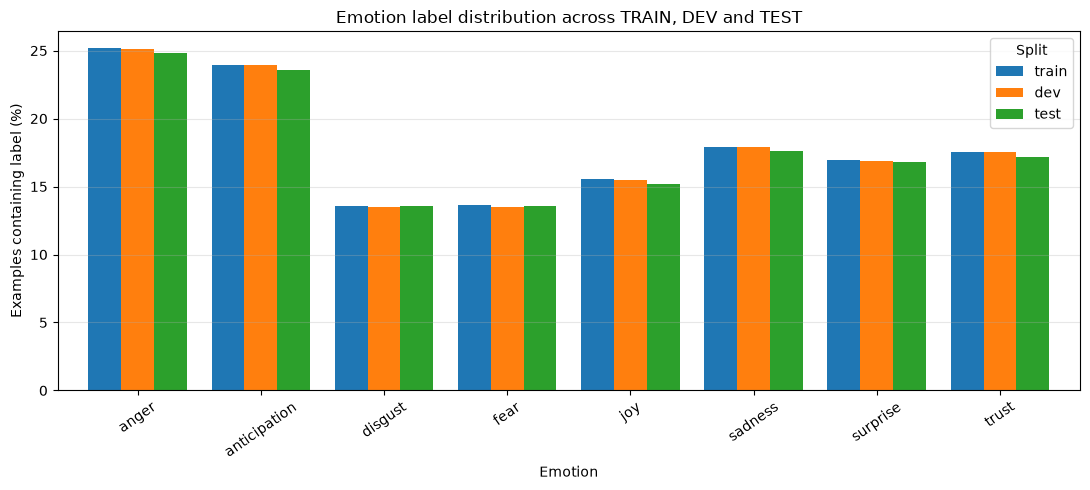

In [27]:
# compare label prevalence across the three splits
ax = percentages.plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_title("Emotion label distribution across TRAIN, DEV and TEST")
ax.set_xlabel("Emotion")
ax.set_ylabel("Examples containing label (%)")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Split")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**How to interpret the chart:** If an emotion appears in 20% of TRAIN and 20% of TEST, its relative frequency is similar across splits. Since this is **multi-label** classification, one subtitle can contribute to more than one emotion; therefore, percentages can add up to more than 100%.

## Training data composition by PEFT condition

The English-only, Swedish-only and bilingual training sets are compared by language and total size. The notebook also validates that bilingual training uses **one version of each aligned subtitle pair** and an approximately even English–Swedish mix.

All counts are read from the actual `train_*.jsonl` files; **DEV and TEST remain unchanged**.


In [28]:
# load each peft training file and count examples by language

def load_records(filename):
    path = DATA_DIR / filename
    with path.open(encoding="utf-8") as file:
        return [json.loads(line) for line in file if line.strip()]


training_files = {
    "English-only": "train_en.jsonl",
    "Swedish-only": f"train_{LANGUAGE}.jsonl",
    "Bilingual": "train_bilingual.jsonl",
}

training_rows = {name: load_records(filename) for name, filename in training_files.items()}

summary = []
for condition, rows in training_rows.items():
    languages = Counter(row.get("language") for row in rows)
    unknown = set(languages) - {"en", LANGUAGE}
    if unknown:
        raise ValueError(f"Unexpected or missing language values in {condition}: {unknown}")

    summary.append({
        "Training condition": condition,
        "English examples": languages["en"],
        "Swedish examples": languages[LANGUAGE],
        "Total examples": len(rows),
    })

training_composition = pd.DataFrame(summary).set_index("Training condition")
display(training_composition)


,English examples,Swedish examples,Total examples
Training condition,,,
English-only,1733,0,1733
Swedish-only,0,1733,1733
Bilingual,867,866,1733


## Balanced training validation

Check that **English-only, Swedish-only and bilingual** use the same number of training examples. The bilingual file must contain exactly one version of each aligned pair, with approximately half the examples in each language. The counts below come directly from the dataset files (they are not hardcoded).


In [29]:
# print the training-size summary and validate alignment-based balancing
english = training_rows["English-only"]
swedish = training_rows["Swedish-only"]
bilingual = training_rows["Bilingual"]
language_counts = Counter(row["language"] for row in bilingual)

print(f"English-only: {len(english)}")
print(f"Swedish-only: {len(swedish)}")
print(f"Bilingual: {len(bilingual)} {language_counts}")

# compare aligned IDs and verify each bilingual row matches its monolingual source
english_by_id = {row["alignment_id"]: row for row in english}
swedish_by_id = {row["alignment_id"]: row for row in swedish}
bilingual_ids = [row["alignment_id"] for row in bilingual]


def label_set(row):
    labels = row["output"]
    return frozenset(json.loads(labels) if isinstance(labels, str) else labels)


same_ids = (
    len(english_by_id) == len(english)
    and len(swedish_by_id) == len(swedish)
    and len(set(bilingual_ids)) == len(bilingual_ids)
    and set(english_by_id) == set(swedish_by_id) == set(bilingual_ids)
)

valid_bilingual_records = all(
    row["alignment_id"] in (english_by_id if row["language"] == "en" else swedish_by_id)
    and row["input"] == (
        english_by_id if row["language"] == "en" else swedish_by_id
    )[row["alignment_id"]]["input"]
    and label_set(row) == (
        label_set(english_by_id[row["alignment_id"]])
        if row["language"] == "en"
        else label_set(swedish_by_id[row["alignment_id"]])
    )
    for row in bilingual
)

checks = {
    "same training size": len(english) == len(swedish) == len(bilingual),
    "balanced languages": abs(language_counts["en"] - language_counts[LANGUAGE]) <= 1,
    "correct monolingual languages": (
        all(row["language"] == "en" for row in english)
        and all(row["language"] == LANGUAGE for row in swedish)
    ),
    "one version of each aligned pair": same_ids,
    "bilingual source texts and labels match": valid_bilingual_records,
}

if all(checks.values()):
    print("Balanced training validation passed")
else:
    print("Balanced training validation FAILED")
    for name, passed in checks.items():
        if not passed:
            print(f"- {name}")


English-only: 1733
Swedish-only: 1733
Bilingual: 1733 Counter({'en': 867, 'sv': 866})
Balanced training validation passed


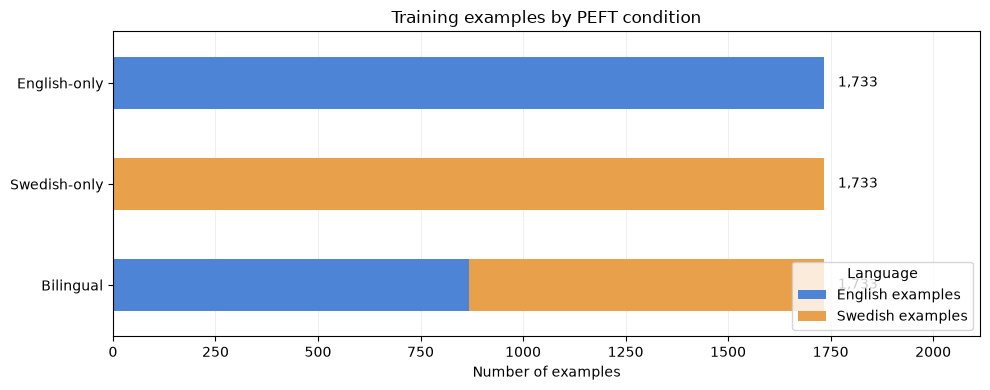

In [30]:
# stacked bars showing the language composition of each training condition
ax = training_composition[["English examples", "Swedish examples"]].plot(
    kind="barh",
    stacked=True,
    figsize=(10, 4),
    color=["#4E84D6", "#E8A04B"],
    width=0.52,
)

ax.invert_yaxis()
ax.set_title("Training examples by PEFT condition")
ax.set_xlabel("Number of examples")
ax.set_ylabel("")
ax.legend(title="Language", loc="lower right")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

max_total = training_composition["Total examples"].max()
ax.set_xlim(0, max_total * 1.22)
for i, total in enumerate(training_composition["Total examples"]):
    ax.text(total + max_total * 0.02, i, f"{total:,}", va="center")

plt.tight_layout()
plt.show()

**Interpretation:** The monolingual adapters each use one language, while the bilingual adapter should use approximately half English and half Swedish, with the **same total number of examples** as each monolingual adapter. Check the validation message above to confirm the balanced dataset is ready.
